In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.impute import KNNImputer
from sklearn.preprocessing import StandardScaler

In [4]:
df_path = "/content/drive/MyDrive/Model/Data sebelum imputasi/Data konsentrasi perjam DKI1 Bundaran HI.xlsx"
df = pd.read_excel(df_path)
df = df.replace('---', np.nan)
pollutant_cols = ['PM10', 'PM2.5', 'SO2', 'CO', 'O3', 'NO', 'NO2', 'NOX']
df[pollutant_cols] = df[pollutant_cols].replace(0, np.nan)
df.head(10)





/tmp/ipykernel_678/1511921937.py:3: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df = df.replace('---', np.nan)


,datetime,PM10,PM2.5,SO2,CO,O3,NO,NO2,NOX,Suhu Udara (°C),Curah Hujan (mm),Suhu Titik Embun (°C),Kelembaban Relatif (%),Kecepatan Angin (m/s),Radiasi Matahari (W/m²)
0,2020-01-01 00:00:00,42.27,71.96,32.90,0.89,39.80,13.73,38.34,28.92,26.020000,1.67,24.520000,91.459999,1.959,0.000000
1,2020-01-01 01:00:00,51.25,88.40,32.32,0.74,43.47,13.41,28.39,23.83,26.170000,1.23,24.459999,90.330002,2.566,0.000000
2,2020-01-01 02:00:00,52.92,17.79,31.92,0.52,43.18,26.39,19.50,29.19,26.610001,0.74,23.920000,85.209999,3.635,0.000000
3,2020-01-01 03:00:00,52.08,7.24,31.38,0.14,53.73,6.49,10.37,7.23,26.760000,0.63,24.059999,85.169998,4.139,0.000000
4,2020-01-01 04:00:00,48.37,5.25,30.95,0.17,53.05,1.77,10.63,6.50,26.629999,0.99,24.219999,86.650002,4.262,0.000000
5,2020-01-01 05:00:00,49.83,2.47,30.68,0.10,59.32,0.44,5.62,2.65,26.930000,1.79,24.240000,85.239998,4.302,0.000000
6,2020-01-01 06:00:00,42.67,1.57,30.49,0.20,55.29,3.95,9.12,7.39,26.900000,2.20,24.240000,85.389999,3.459,30.510000
7,2020-01-01 07:00:00,33.75,4.90,30.67,0.25,51.41,5.02,11.32,9.26,26.870001,1.16,24.420000,86.470001,2.911,99.120003
8,2020-01-01 08:00:00,22.96,4.35,30.63,0.55,42.57,8.46,17.62,14.89,27.110001,1.38,24.190001,84.089996,2.637,159.699997
9,2020-01-01 09:00:00,12.83,10.53,31.87,0.64,42.37,16.68,27.58,25.88,27.209999,0.99,24.160000,83.449997,2.311,194.419998


In [5]:
for col in df.columns:
    if col != 'datetime':
        df[col] = pd.to_numeric(df[col], errors='coerce')
print(df.dtypes)

datetime                   datetime64[ns]
PM10                              float64
PM2.5                             float64
SO2                               float64
CO                                float64
O3                                float64
NO                                float64
NO2                               float64
NOX                               float64
Suhu Udara (°C)                   float64
Curah Hujan (mm)                  float64
Suhu Titik Embun (°C)             float64
Kelembaban Relatif (%)            float64
Kecepatan Angin (m/s)             float64
Radiasi Matahari (W/m²)           float64
dtype: object


In [6]:
df.isnull().sum()



,0
datetime,0
PM10,341
PM2.5,1203
SO2,851
CO,1033
O3,948
NO,887
NO2,637
NOX,626
Suhu Udara (°C),0


In [7]:
missing_percent = df.isnull().mean() * 100
missing_percent_str = missing_percent.round(2).astype(str) + ' %'
(missing_percent.round(2)).astype(str) + ' %'


,0
datetime,0.0 %
PM10,0.78 %
PM2.5,2.74 %
SO2,1.94 %
CO,2.36 %
O3,2.16 %
NO,2.02 %
NO2,1.45 %
NOX,1.43 %
Suhu Udara (°C),0.0 %


In [8]:
df_numeric = df.select_dtypes(include='number')
df_numeric.describe().round(2)

,PM10,PM2.5,SO2,CO,O3,NO,NO2,NOX,Suhu Udara (°C),Curah Hujan (mm),Suhu Titik Embun (°C),Kelembaban Relatif (%),Kecepatan Angin (m/s),Radiasi Matahari (W/m²)
count,43507.00,42645.00,42997.00,42815.00,42900.00,42961.00,43211.00,43222.00,43848.00,43848.00,43848.00,43848.00,43848.00,43848.00
mean,55.06,32.64,31.98,1.06,54.62,19.37,38.78,33.24,27.69,0.23,23.81,80.04,2.28,221.70
std,22.45,19.04,15.99,0.72,39.03,21.42,23.04,22.88,1.78,0.53,0.86,9.02,1.22,295.30
min,0.74,0.01,0.03,0.01,0.06,0.01,0.05,0.64,23.58,0.00,17.99,40.53,0.01,0.00
25%,37.56,18.37,20.61,0.53,27.99,5.21,21.24,17.13,26.20,0.00,23.41,74.02,1.36,0.00
50%,53.78,30.54,32.11,0.87,44.90,12.00,34.87,27.26,27.40,0.04,23.89,81.76,2.04,12.76
75%,69.56,43.88,43.06,1.46,69.83,25.82,52.49,43.37,29.02,0.20,24.35,87.61,3.02,444.98
max,190.00,665.03,400.70,8.18,1314.40,494.55,350.68,539.79,33.85,14.44,26.18,96.75,7.79,1045.66


In [9]:
df['datetime'] = pd.to_datetime(df['datetime'], errors='coerce')
df_ts = df.set_index('datetime')
df_ts = df_ts.apply(pd.to_numeric, errors='coerce')

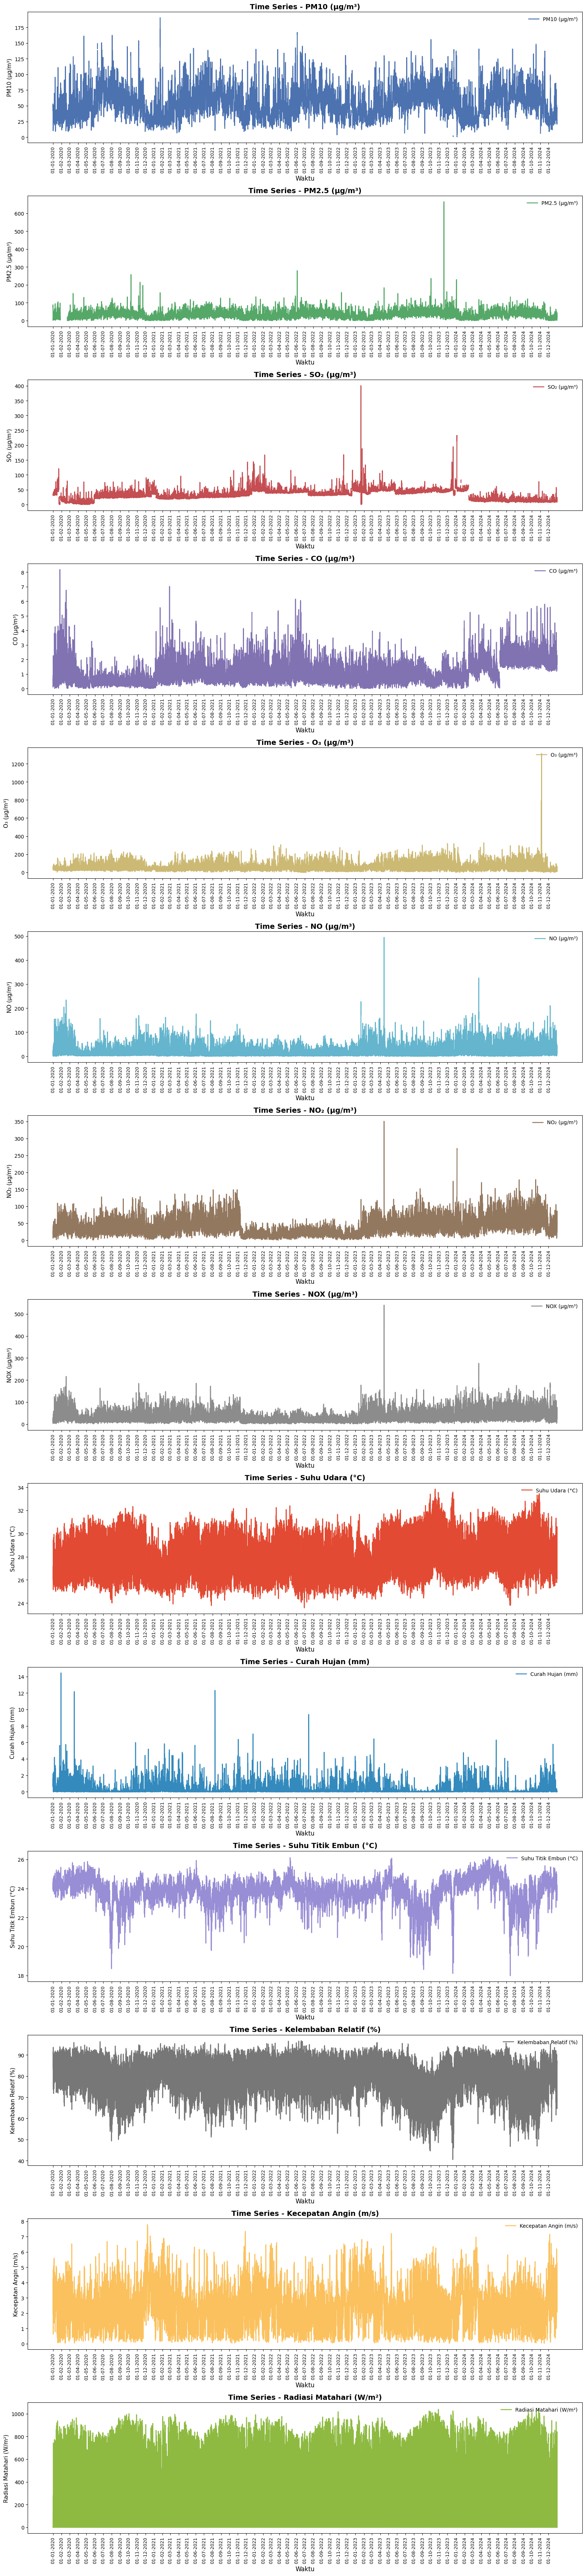

In [10]:
if not isinstance(df_ts.index, pd.DatetimeIndex):
    df_ts.index = pd.to_datetime(df_ts.index)

df_ts = df_ts.sort_index()
hours = (df_ts.index - df_ts.index.min()) / pd.Timedelta(hours=1)
xticks = pd.date_range(start=df_ts.index.min().normalize(),
                       end=df_ts.index.max().normalize(), freq="MS")
labels = [d.strftime('%d-%m-%Y') for d in xticks]


xticks_hours = (xticks - df_ts.index.min()) / pd.Timedelta(hours=1)

colors = [
    "#4C72B0", "#55A868", "#C44E52", "#8172B2", "#CCB974",
    "#64B5CD", "#937860", "#8C8C8C", "#E24A33", "#348ABD",
    "#988ED5", "#777777", "#FBC15E", "#8EBA42", "#FFB5B8"
]
if len(df_ts.columns) > len(colors):
    colors = (colors * (len(df_ts.columns) // len(colors) + 1))[:len(df_ts.columns)]

label_map = {
    'datetime': 'Tanggal & Waktu',
    'PM10': 'PM10 (µg/m³)',
    'PM2.5': 'PM2.5 (µg/m³)',
    'SO2': 'SO₂ (µg/m³)',
    'CO': 'CO (µg/m³)',
    'O3': 'O₃ (µg/m³)',
    'NO': 'NO (µg/m³)',
    'NO2': 'NO₂ (µg/m³)',
    'NOX': 'NOX (µg/m³)'
}

fig, axes = plt.subplots(
    nrows=len(df_ts.columns),
    figsize=(16, 5 * len(df_ts.columns)),
    sharex=False
)

if len(df_ts.columns) == 1:
    axes = [axes]

for ax, col, color in zip(axes, df_ts.columns, colors):
    ax.plot(hours, df_ts[col], color=color, linewidth=1.8, label=label_map.get(col, col))
    ax.set_title(f"Time Series - {label_map.get(col, col)}", fontsize=14, fontweight='bold')
    ax.set_ylabel(label_map.get(col, col), fontsize=11)
    ax.legend(loc="upper right", fontsize=10, frameon=False)
    ax.set_xticks(xticks_hours)
    ax.set_xticklabels(labels, rotation=90, ha="center", fontsize=9)

for ax in axes:
    ax.set_xlabel("Waktu", fontsize=12)

plt.tight_layout()
plt.show()


In [13]:
df['datetime'] = pd.to_datetime(df['datetime'])
datetime_index = df['datetime']
numeric_cols = df.select_dtypes(include=[np.number]).columns
df_numeric = df[numeric_cols]

scaler = StandardScaler()
df_scaled = scaler.fit_transform(df_numeric)

In [14]:
imputer = KNNImputer(n_neighbors=5)
df_imputed_scaled = imputer.fit_transform(df_scaled)

In [15]:
df_imputed_numeric = pd.DataFrame(
    scaler.inverse_transform(df_imputed_scaled),
    columns=numeric_cols
)

In [16]:
df_imputed = df_imputed_numeric.copy()
df_imputed.index = datetime_index
df_imputed.head(10)

,PM10,PM2.5,SO2,CO,O3,NO,NO2,NOX,Suhu Udara (°C),Curah Hujan (mm),Suhu Titik Embun (°C),Kelembaban Relatif (%),Kecepatan Angin (m/s),Radiasi Matahari (W/m²)
datetime,,,,,,,,,,,,,,
2020-01-01 00:00:00,42.27,71.96,32.90,0.89,39.80,13.73,38.34,28.92,26.020000,1.67,24.520000,91.459999,1.959,0.000000
2020-01-01 01:00:00,51.25,88.40,32.32,0.74,43.47,13.41,28.39,23.83,26.170000,1.23,24.459999,90.330002,2.566,0.000000
2020-01-01 02:00:00,52.92,17.79,31.92,0.52,43.18,26.39,19.50,29.19,26.610001,0.74,23.920000,85.209999,3.635,0.000000
2020-01-01 03:00:00,52.08,7.24,31.38,0.14,53.73,6.49,10.37,7.23,26.760000,0.63,24.059999,85.169998,4.139,0.000000
2020-01-01 04:00:00,48.37,5.25,30.95,0.17,53.05,1.77,10.63,6.50,26.629999,0.99,24.219999,86.650002,4.262,0.000000
2020-01-01 05:00:00,49.83,2.47,30.68,0.10,59.32,0.44,5.62,2.65,26.930000,1.79,24.240000,85.239998,4.302,0.000000
2020-01-01 06:00:00,42.67,1.57,30.49,0.20,55.29,3.95,9.12,7.39,26.900000,2.20,24.240000,85.389999,3.459,30.510000
2020-01-01 07:00:00,33.75,4.90,30.67,0.25,51.41,5.02,11.32,9.26,26.870001,1.16,24.420000,86.470001,2.911,99.120003
2020-01-01 08:00:00,22.96,4.35,30.63,0.55,42.57,8.46,17.62,14.89,27.110001,1.38,24.190001,84.089996,2.637,159.699997


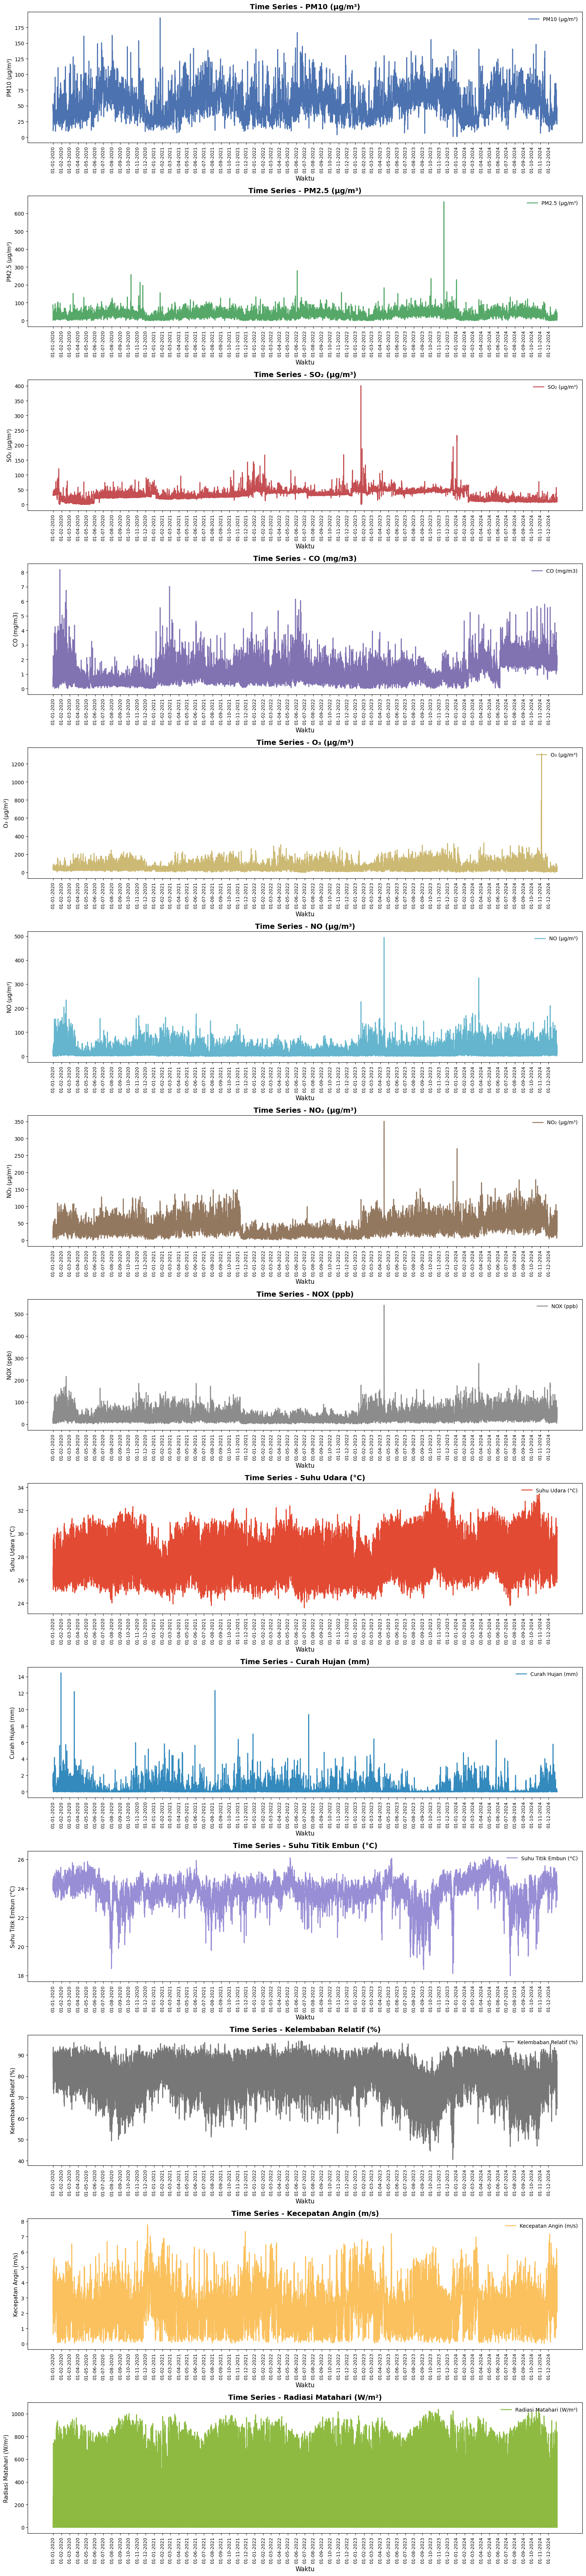

In [17]:
if not isinstance(df_imputed.index, pd.DatetimeIndex):
    df_imputed.index = pd.to_datetime(df_imputed.index)

df_imputed = df_imputed.sort_index()

hours = (df_imputed.index - df_imputed.index.min()) / pd.Timedelta(hours=1)

xticks = pd.date_range(start=df_imputed.index.min().normalize(),
                       end=df_imputed.index.max().normalize(),
                       freq="MS")
labels = [d.strftime('%d-%m-%Y') for d in xticks]
xticks_hours = (xticks - df_imputed.index.min()) / pd.Timedelta(hours=1)

colors = [
    "#4C72B0", "#55A868", "#C44E52", "#8172B2", "#CCB974",
    "#64B5CD", "#937860", "#8C8C8C", "#E24A33", "#348ABD",
    "#988ED5", "#777777", "#FBC15E", "#8EBA42", "#FFB5B8"
]
if len(df_imputed.columns) > len(colors):
    colors = (colors * (len(df_imputed.columns) // len(colors) + 1))[:len(df_imputed.columns)]

label_map = {
    'datetime': 'Tanggal & Waktu',
    'PM10': 'PM10 (µg/m³)',
    'PM2.5': 'PM2.5 (µg/m³)',
    'SO2': 'SO₂ (µg/m³)',
    'CO': 'CO (mg/m3)',
    'O3': 'O₃ (µg/m³)',
    'NO': 'NO (µg/m³)',
    'NO2': 'NO₂ (µg/m³)',
    'NOX': 'NOX (ppb)'
}

fig, axes = plt.subplots(
    nrows=len(df_imputed.columns),
    figsize=(16, 5 * len(df_imputed.columns)),
    sharex=False
)

if len(df_imputed.columns) == 1:
    axes = [axes]

for ax, col, color in zip(axes, df_imputed.columns, colors):
    ax.plot(hours, df_imputed[col], color=color, linewidth=1.8, label=label_map.get(col, col))
    ax.set_title(f"Time Series - {label_map.get(col, col)}", fontsize=14, fontweight='bold')
    ax.set_ylabel(label_map.get(col, col), fontsize=11)
    ax.legend(loc="upper right", fontsize=10, frameon=False)
    ax.set_xticks(xticks_hours)
    ax.set_xticklabels(labels, rotation=90, ha="center", fontsize=9)

for ax in axes:
    ax.set_xlabel("Waktu", fontsize=12)

plt.tight_layout()
plt.show()

In [18]:
df_imputed.describe().round(2)

,PM10,PM2.5,SO2,CO,O3,NO,NO2,NOX,Suhu Udara (°C),Curah Hujan (mm),Suhu Titik Embun (°C),Kelembaban Relatif (%),Kecepatan Angin (m/s),Radiasi Matahari (W/m²)
count,43848.00,43848.00,43848.00,43848.00,43848.00,43848.00,43848.00,43848.00,43848.00,43848.00,43848.00,43848.00,43848.00,43848.00
mean,55.08,32.44,31.96,1.06,54.64,19.26,38.75,33.21,27.69,0.23,23.81,80.04,2.28,221.70
std,22.42,18.95,15.91,0.72,38.94,21.30,22.96,22.79,1.78,0.53,0.86,9.02,1.22,295.30
min,0.74,0.01,0.03,0.01,0.06,0.01,0.05,0.64,23.58,0.00,17.99,40.53,0.01,0.00
25%,37.63,18.22,20.69,0.53,28.07,5.17,21.30,17.19,26.20,0.00,23.41,74.02,1.36,0.00
50%,53.83,30.34,32.09,0.87,44.90,11.95,34.87,27.28,27.40,0.04,23.89,81.76,2.04,12.76
75%,69.56,43.64,42.94,1.45,69.84,25.64,52.38,43.26,29.02,0.20,24.35,87.61,3.02,444.98
max,190.00,665.03,400.70,8.18,1314.40,494.55,350.68,539.79,33.85,14.44,26.18,96.75,7.79,1045.66


In [21]:
df_imputed.loc[:, ~df_imputed.columns.isin(['NO', 'NOX'])].describe().round(2)

,PM10,PM2.5,SO2,CO,O3,NO2,Suhu Udara (°C),Curah Hujan (mm),Suhu Titik Embun (°C),Kelembaban Relatif (%),Kecepatan Angin (m/s),Radiasi Matahari (W/m²)
count,43848.00,43848.00,43848.00,43848.00,43848.00,43848.00,43848.00,43848.00,43848.00,43848.00,43848.00,43848.00
mean,55.08,32.44,31.96,1.06,54.64,38.75,27.69,0.23,23.81,80.04,2.28,221.70
std,22.42,18.95,15.91,0.72,38.94,22.96,1.78,0.53,0.86,9.02,1.22,295.30
min,0.74,0.01,0.03,0.01,0.06,0.05,23.58,0.00,17.99,40.53,0.01,0.00
25%,37.63,18.22,20.69,0.53,28.07,21.30,26.20,0.00,23.41,74.02,1.36,0.00
50%,53.83,30.34,32.09,0.87,44.90,34.87,27.40,0.04,23.89,81.76,2.04,12.76
75%,69.56,43.64,42.94,1.45,69.84,52.38,29.02,0.20,24.35,87.61,3.02,444.98
max,190.00,665.03,400.70,8.18,1314.40,350.68,33.85,14.44,26.18,96.75,7.79,1045.66


In [ ]:
df_imputed['datetime'] = df_imputed.index
df_imputed.to_excel(
    "/content/drive/MyDrive/Model/Data Imputasi 2/df_imputed.xlsx",
    index=False
)



